This notebook is used for the creation of model boundary conditions for the Alaska North Slope model. Just as for the initial condition, the boundary condition vector quantities need to rotated on the curvilinear model domain. 

First, import packages necessary for this notebook:

In [1]:
# import the modules for computation, plotting, and reading files
import os
import numpy as np
import matplotlib.pyplot as plt
import netCDF4 as nc4
import cmocean.cm as cm

# import the necessary modules from eccoseas
from eccoseas.ecco import io
from eccoseas.ecco import grid as eeg
from eccoseas.downscale import hFac
from eccoseas.downscale import horizontal
from eccoseas.downscale import vertical
from eccoseas.toolbox import reprojection

## Constructing the Boundary Conditions
For this model, we will use a model output from the ECCO-Darwin LLC270 state estimate. We will prepare the boundary condition fields in 7 steps:
1. download the model output prepared using the [diagnostics_vec](https://github.com/mhwood/diagnostics_vec) package
2. read the LLC270 model grid
3. read in the bathymetry for the regional model as well as its grid
4. prepare the ECCO-Darwin fields for interpolation
5. interpolate the ECCO-Darwin fields onto the regional model grid and store each as a binary file
6. plot the interpolated fields to ensure they look as expected

### Step 1: Download the ECCO fields
To begin, I downloaded the model fields generated with `diagnostics_vec` from ECCO-Darwin:

There are stored in the following directory:

In [2]:
run_folder = '../../../configurations/alaska_north_slope/run'

### Step 2: Read in the ECCO grid
To read in the ECCO fields, I will rely on the `io` module from the `eccoseas.ecco` package:

In [3]:
data_folder = '../../../data/alaskan_north_slope'

In [4]:
ecco_XC_faces, ecco_YC_faces, ecco_AngleCS_faces, ecco_AngleSN_faces, ecco_hFacC_faces, ecco_hFacW_faces, ecco_hFacS_faces =\
     io.read_ecco_geometry_to_faces(data_folder, llc=270, Nr=50)

In [5]:
ecco_XC_tiles = eeg.ecco_faces_to_tiles(ecco_XC_faces, llc=270, dim=2)
ecco_YC_tiles = eeg.ecco_faces_to_tiles(ecco_YC_faces, llc=270, dim=2)
ecco_AngleCS_tiles = eeg.ecco_faces_to_tiles(ecco_AngleCS_faces, llc=270, dim=2)
ecco_AngleSN_tiles = eeg.ecco_faces_to_tiles(ecco_AngleSN_faces, llc=270, dim=2)
ecco_hFacC_tiles = eeg.ecco_faces_to_tiles(ecco_hFacC_faces, llc=270, dim=3)
ecco_hFacS_tiles = eeg.ecco_faces_to_tiles(ecco_hFacS_faces, llc=270, dim=3)
ecco_hFacW_tiles = eeg.ecco_faces_to_tiles(ecco_hFacW_faces, llc=270, dim=3)
ecco_RF = np.fromfile(os.path.join(data_folder,'RF.data'), '>f4')
ecco_DRF = np.fromfile(os.path.join(data_folder,'DRF.data'), '>f4')
ecco_Nr = len(ecco_RF)-1

### Step 3: Read in the Model Grid and Generate a Mask
Here, I will read in the grid to use in the model. This was generated by running the model for one timestep and then creating an nc file.

In [6]:
# define the parameters that will be used in the data file
ds = nc4.Dataset('../../../data/alaskan_north_slope/NorthSlope_ncgrid.nc')
XC = ds.variables['XC'][:, :]
YC = ds.variables['YC'][:, :]
bathy = -1*ds.variables['Depth'][:,:]
AngleCS = ds.variables['AngleCS'][:,:]
AngleSN = ds.variables['AngleSN'][:,:]
hFacC = ds.variables['HFacC'][:, :, :]
hFacW = ds.variables['HFacW'][:, :, :]
hFacS = ds.variables['HFacS'][:, :, :]
delR = ds.variables['drF'][:]
ds.close()

# remove the extra row and col from hFacS and hFacW
hFacS = hFacS[:,:-1,:]
hFacW = hFacW[:,:,:-1]

As in the initial condition notebook, we will make masks by setting all of the non-zero `hFac` points to 1:

In [7]:
# generate the masks
maskC = np.copy(hFacC)
maskC[maskC>0] = 1

maskS = np.copy(hFacS)
maskS[maskS>0] = 1

maskW = np.copy(hFacW)
maskW[maskW>0] = 1

Similarly, we will also reproject the grid to avoid interpolation artefacts:

In [8]:
utm_zone_epsg = 32606
regional_coordinates = reprojection.reproject_polygon(np.column_stack([XC.ravel(), YC.ravel()]), 4326, utm_zone_epsg)
X = regional_coordinates[:,0].reshape(np.shape(XC))
Y = regional_coordinates[:,1].reshape(np.shape(XC))

### Step 4: Prepare the grids for interpolation

Next, we subset the ECCO points using the masks used in diagnostics_vec. This gives us the source locations of each grid:

In [9]:
# define the boundary list
boundary_list = ['east', 'north', 'west']

In [10]:
# make a dictionary to fill in with the domain info on the boundaries
boundary_domain_dict = {}

# loop through each boundary
for boundary in boundary_list:

    # read in the mask
    dv_mask_faces = io.read_ecco_field_to_faces(os.path.join(run_folder,'dv',
                                                             boundary+'_BC_mask.bin'),
                                                llc=270, dim=2, Nr=50,dtype='>f4')
    dv_mask_tiles = eeg.ecco_faces_to_tiles(dv_mask_faces, llc=270, dim=2)
    
    # determine the number of points in each set
    total_points = 0
    for tile in range(1,14):
        total_points += np.sum(dv_mask_tiles[tile]!=0)

    # make empty arrays to fill in
    ecco_XC_points = np.zeros((total_points, ))
    ecco_YC_points = np.zeros((total_points, ))
    ecco_AngleCS_points = np.zeros((total_points, ))
    ecco_AngleSN_points = np.zeros((total_points, ))
    ecco_maskC_points = np.zeros((ecco_Nr, total_points))
    ecco_maskW_points = np.zeros((ecco_Nr, total_points))
    ecco_maskS_points = np.zeros((ecco_Nr, total_points))

    # loop through the mask and fill in the points used for interpolation
    for tile_number in range(1,14):
        dv_rows, dv_cols = np.where(dv_mask_tiles[tile_number]!=0)
        if len(dv_rows)>0:

            for row, col in zip(dv_rows, dv_cols):
                ecco_XC_points[int(dv_mask_tiles[tile_number][row,col])-1] = ecco_XC_tiles[tile_number][row,col]
                ecco_YC_points[int(dv_mask_tiles[tile_number][row,col])-1] = ecco_YC_tiles[tile_number][row,col]
                ecco_AngleCS_points[int(dv_mask_tiles[tile_number][row,col])-1] = ecco_AngleCS_tiles[tile_number][row,col]
                ecco_AngleSN_points[int(dv_mask_tiles[tile_number][row,col])-1] = ecco_AngleSN_tiles[tile_number][row,col]

                for k in range(ecco_Nr):
                    ecco_maskC_points[k, int(dv_mask_tiles[tile_number][row,col])-1] = ecco_hFacC_tiles[tile_number][k, row,col]
                    ecco_maskW_points[k, int(dv_mask_tiles[tile_number][row,col])-1] = ecco_hFacW_tiles[tile_number][k, row,col]
                    ecco_maskS_points[k, int(dv_mask_tiles[tile_number][row,col])-1] = ecco_hFacS_tiles[tile_number][k, row,col]

    # convert hFac to a mask
    ecco_maskC_points[ecco_maskC_points>0]=1
    ecco_maskW_points[ecco_maskW_points>0]=1
    ecco_maskS_points[ecco_maskS_points>0]=1

    # store the grid information into the dictionary above
    boundary_domain_dict[boundary] = {'XC': ecco_XC_points,
                                      'YC': ecco_YC_points,
                                      'AngleCS': ecco_AngleCS_points,
                                      'AngleSN': ecco_AngleSN_points,
                                      'maskC': ecco_maskC_points,
                                      'maskW': ecco_maskW_points,
                                      'maskS': ecco_maskS_points }

Next, we'll plot these to make sure everything looks ok:

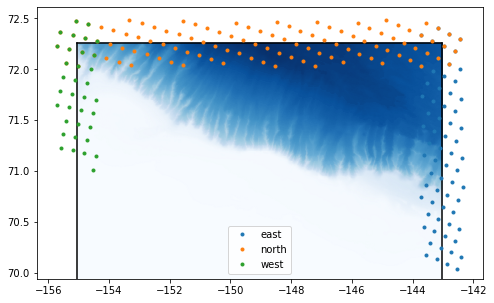

In [11]:
fig = plt.figure(figsize=(8,5))
plt.pcolormesh(XC,YC,bathy, cmap='Blues_r', alpha=0.3, shading='gouraud')
for boundary in boundary_list:
    if boundary=='west':
        plt.plot(XC[:,0], YC[:,0], 'k-')
    if boundary=='east':
        plt.plot(XC[:,-1], YC[:,-1], 'k-')
    if boundary=='north':
        plt.plot(XC[-1, :], YC[-1, :], 'k-')
    ecco_XC = boundary_domain_dict[boundary]['XC']
    ecco_YC = boundary_domain_dict[boundary]['YC']
    plt.plot(ecco_XC, ecco_YC, '.', label=boundary)
plt.legend()
plt.show()

Looks good!

Next, we'll read in the data fields and apply the modifications as necessary for the vector quantities. Let's make a quick function for the i/o:

In [36]:
def read_dv_output_grid(dv_dir, var_name, boundary, boundary_domain_dict):

    # manual list for now but should be generalized
    iter_numbers = [683785, 710065]

    if var_name in ['AREA','UICE','VICE','HEFF','HSNOW','ETAN']:
        Nr = 1
    else:
        Nr = ecco_Nr

    for iter_number in iter_numbers:
        if 'VEL' in var_name or 'ICE' in var_name:
            suffix = var_name[-3:]
            dv_grid_u = np.fromfile(os.path.join(dv_dir,boundary+'_BC_mask_U'+suffix+'.'+'{:010d}'.format(iter_number)+'.bin'), '>f4')
            n_mask_points = len(boundary_domain_dict[boundary]['XC'])
            timesteps = int(np.size(dv_grid_u)/(Nr*n_mask_points))
            dv_grid_u = np.reshape(dv_grid_u, (timesteps, Nr, n_mask_points))
            dv_grid_v = np.fromfile(os.path.join(dv_dir,boundary+'_BC_mask_V'+suffix+'.'+'{:010d}'.format(iter_number)+'.bin'), '>f4')
            dv_grid_v = np.reshape(dv_grid_v, (timesteps, Nr, n_mask_points))
            dv_grid = np.zeros((timesteps, Nr, n_mask_points))
            if var_name in ['UVEL','UICE']:
                for m in range(n_mask_points):
                    dv_grid[:,:,m] = boundary_domain_dict[boundary]['AngleCS'][m] * dv_grid_u[:,:,m] -\
                                     boundary_domain_dict[boundary]['AngleSN'][m] * dv_grid_v[:,:,m]
            if var_name in ['VVEL','VICE']:
                for m in range(n_mask_points):
                    dv_grid[:,:,m] = boundary_domain_dict[boundary]['AngleSN'][m] * dv_grid_u[:,:,m] +\
                                     boundary_domain_dict[boundary]['AngleCS'][m] * dv_grid_v[:,:,m]
        else:
            dv_grid = np.fromfile(os.path.join(dv_dir,boundary+'_BC_mask_'+var_name+'.'+'{:010d}'.format(iter_number)+'.bin'), '>f4')
            n_mask_points = len(boundary_domain_dict[boundary]['XC'])
            timesteps = int(np.size(dv_grid)/(Nr*n_mask_points))
            dv_grid = np.reshape(dv_grid, (timesteps, Nr, n_mask_points))
            
        if iter_number==iter_numbers[0]:
            dv_grid_all = dv_grid
        else:
            dv_grid = np.concatenate([dv_grid_all, dv_grid], axis=0)

    # interpolate vertically if need be
    if variable_name == 'UVEL' or variable_name == 'UICE':
        ecco_mask_points = boundary_domain_dict[boundary]['maskW']
    elif variable_name == 'VVEL' or variable_name == 'VICE':
        ecco_mask_points = boundary_domain_dict[boundary]['maskS']
    else:
        ecco_mask_points = boundary_domain_dict[boundary]['maskC']
    
    if variable_name not in ['AREA','UICE','VICE','HEFF','HSNOW', 'ETAN']:
        print('         - Interpolating to new depth levels')
        dv_grid_interp = np.zeros((np.shape(dv_grid)[0], len(delR), np.shape(dv_grid)[2]))
        for t in range(np.shape(dv_grid)[0]):
            dv_grid_interp[t,:,:], ecco_mask_points_interp = \
             vertical.interpolate_var_grid_faces_to_new_depth_levels(dv_grid[t,:,:], ecco_mask_points,
                                                                 np.array(ecco_DRF), np.array(delR))
    else:
        ecco_mask_points = ecco_mask_points[:1,:]
        dv_grid_interp = dv_grid
        ecco_mask_points_interp = ecco_mask_points

    return(dv_grid_interp, ecco_mask_points_interp)

### Step 5: Interpolate the Fields onto the Model Grid
Next, we will interpolate the ECCO-Darwin fields onto the regional model domain. We will use the `horizontal` module from the `eccoseas` package to accomplish this interpolation.

In [37]:
input_dir = '../../../configurations/alaska_north_slope/input/'

In [38]:
if 'obcs' not in os.listdir(input_dir):
    os.mkdir(os.path.join(input_dir,'obcs'))

In [39]:
testing=True
if testing:
    print('WARNING - IN TESTING MODE - ONLY INTERPOLATING THE FIRST TIMESTEP!')

variable_names = ['THETA','SALT','UVEL','VVEL',
                  'AREA','HEFF','HSNOW','UICE','VICE']

for tracer_number in range(1,5):
    variable_names.append('PTRACE'+'{:02d}'.format(tracer_number))

# loop through each variable
for variable_name in variable_names:

    print('Creating the boundary conditions for '+variable_name)
    # loop through each boundary
    for boundary in boundary_list:

        output_file = os.path.join(input_dir,'obcs',variable_name+'_'+boundary+'.bin')
        
        # only run the routine if the file hasn't been made yet
        if not os.path.exists(output_file):

            print('  - Working on the '+boundary+' boundary')
            ecco_XC_points = boundary_domain_dict[boundary]['XC']
            ecco_YC_points = boundary_domain_dict[boundary]['YC']
            utm_coordinates = reprojection.reproject_polygon(np.column_stack([ecco_XC_points, ecco_YC_points]), 4326, utm_zone_epsg)
    
            # read in the dv grid using the function defined above
            print('     - Reading in the dv grid')
            dv_grid, ecco_mask_points = read_dv_output_grid(os.path.join(run_folder, 'dv'), variable_name, boundary, boundary_domain_dict)
            n_timesteps = np.shape(dv_grid)[0]
            
            if variable_name == 'UVEL' or variable_name == 'UICE':
                mask = maskW
            elif variable_name == 'VVEL' or variable_name == 'VICE':
                mask = maskS
            else:
                mask = maskC
        
            if boundary == 'west':
                boundary_X = X[:,:1]
                boundary_Y = Y[:,:1]
                boundary_mask = mask[:,:,:1]
            elif boundary == 'east':
                boundary_X = X[:,-1:]
                boundary_Y = Y[:,-1:]
                boundary_mask = mask[:,:,-1:]
            elif boundary == 'north':
                boundary_X = X[-1:,:]
                boundary_Y = Y[-1:,:]
                boundary_mask = mask[:,-1:,:]
            elif boundary == 'south':
                boundary_X = X[:1,:]
                boundary_Y = Y[:1,:]
                boundary_mask = mask[:,:1,:]
            else:
                raise ValueError('Boundary '+boundary+' not recognized')

            if variable_name in ['AREA','UICE','VICE','HEFF','HSNOW', 'ETAN']:
                boundary_mask = boundary_mask[:1,:,:]
                output_grid = np.zeros((n_timesteps, 1, np.size(boundary_X)))
            else:
                output_grid = np.zeros((n_timesteps, np.size(delR), np.size(boundary_X)))
        
            print('     - Interpolating horizontally')
            if testing:
                timesteps = 1
            else:
                timesteps = n_timesteps
                
            for t in range(timesteps):
                interpolated_grid = horizontal.downscale_3D_points(utm_coordinates,
                                                                   dv_grid[t,:,:], ecco_mask_points, 
                                                                   boundary_X, boundary_Y, boundary_mask)
                for k in range(np.shape(output_grid)[1]):
                    output_grid[t,k,:] = interpolated_grid[k,:,:].ravel()

            # output the interpolated grid
            output_grid.ravel('C').astype('>f4').tofile(output_file)

WARNING - IN TESTING MODE - ONLY INTERPOLATING THE FIRST TIMESTEP!
Creating the boundary conditions for THETA
Creating the boundary conditions for SALT
Creating the boundary conditions for UVEL
  - Working on the east boundary
     - Reading in the dv grid
         - Interpolating to new depth levels
     - Interpolating horizontally
  - Working on the north boundary
     - Reading in the dv grid
         - Interpolating to new depth levels
     - Interpolating horizontally
  - Working on the west boundary
     - Reading in the dv grid
         - Interpolating to new depth levels
     - Interpolating horizontally
Creating the boundary conditions for VVEL
  - Working on the east boundary
     - Reading in the dv grid
         - Interpolating to new depth levels
     - Interpolating horizontally
  - Working on the north boundary
     - Reading in the dv grid
         - Interpolating to new depth levels
     - Interpolating horizontally
  - Working on the west boundary
     - Reading in t

### Step 6: Plotting the Boundary Fields
Now that the fields have been generated, plot them to ensure they look as expected. 

#### Physical Parameters

First, generate some metadata for each one:

In [40]:
pmeta_dict = {'THETA':[-2, 2, 'turbo', 'm'],
            'SALT':[31, 36, 'viridis', 'm'],
            'UVEL':[-0.05, 0.05, 'seismic', 'm'],
            'VVEL':[-0.05, 0.05, 'seismic', 'm']}

Then, create all of the subplots:

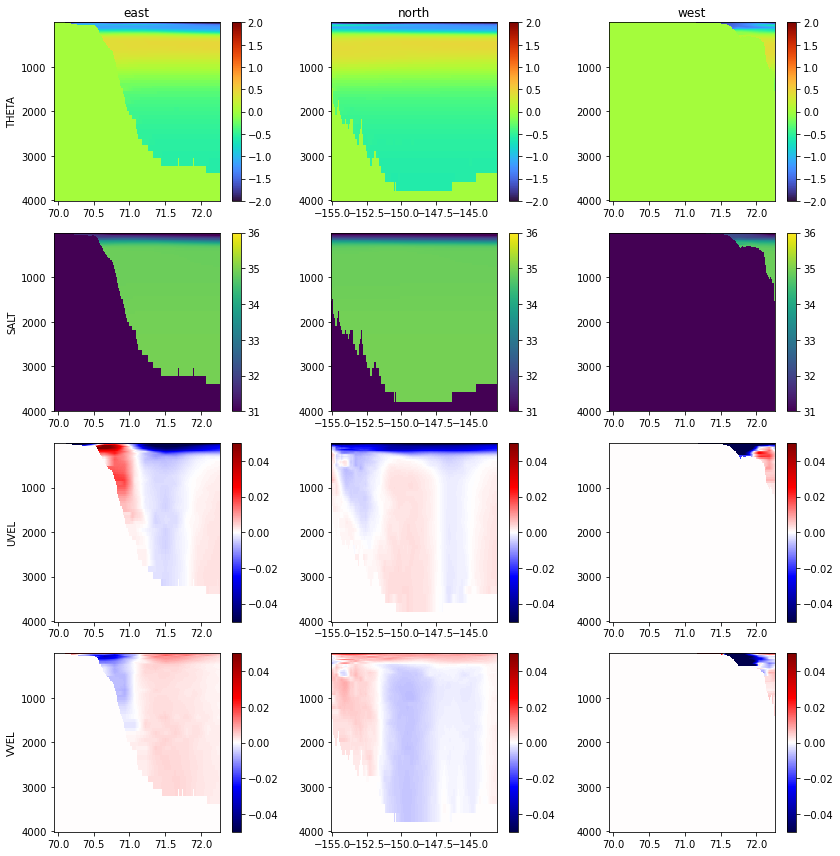

In [41]:
fig = plt.figure(figsize=(12,12))

plot_variable_names = ['THETA','SALT','UVEL','VVEL']

Z = np.cumsum(delR)
plot_counter = 0
for i in range(len(plot_variable_names)):
    variable_name = plot_variable_names[i]
    
    for boundary in boundary_list:
        
        boundary_grid = np.fromfile(os.path.join(input_dir,'obcs',variable_name+'_'+boundary+'.bin'),'>f4')
    
        if boundary in ['west','east']:
            boundary_grid = boundary_grid.reshape((n_timesteps, np.shape(delR)[0],np.shape(XC)[0]))
            boundary_grid = boundary_grid[0, :, :] # choose just the first timestep for plotting
            if boundary=='west':
                x = YC[:,1]
            if boundary=='east':
                x = YC[:,-1]
        else:
            boundary_grid = boundary_grid.reshape((n_timesteps, np.shape(delR)[0],np.shape(XC)[1]))
            boundary_grid = boundary_grid[0, :, :] # choose just the first timestep for plotting
            if boundary=='north':
                x = XC[-1,:]
            if boundary=='south':
                x = XC[1,:]

        plot_counter += 1
        plt.subplot(len(plot_variable_names),len(boundary_list),plot_counter)
        C = plt.pcolormesh(x, Z, boundary_grid,
                           vmin=meta_dict[variable_name][0],
                           vmax=meta_dict[variable_name][1],
                           cmap=meta_dict[variable_name][2])
        plt.colorbar(C,fraction=0.26)
        plt.gca().invert_yaxis()
    
        if plot_counter%3==1:
            plt.ylabel(variable_name)
        if plot_counter<4:
            plt.title(boundary)

plt.tight_layout()

plt.show()

#### Tracers

Next, we'll plot a few of the tracers:

In [30]:
meta_dict = {'PTRACE01':[1900, 2250, 'turbo', '$\\mu$M C'],
            'PTRACE02':[3, 16, 'BuPu', '$\\mu$M N'],
            'PTRACE03':[0, 0.04, 'BuPu', '$\\mu$M N'],
            'PTRACE04':[0, 0.02, 'BuPu', '$\\mu$M N']}

Let's see how they look:

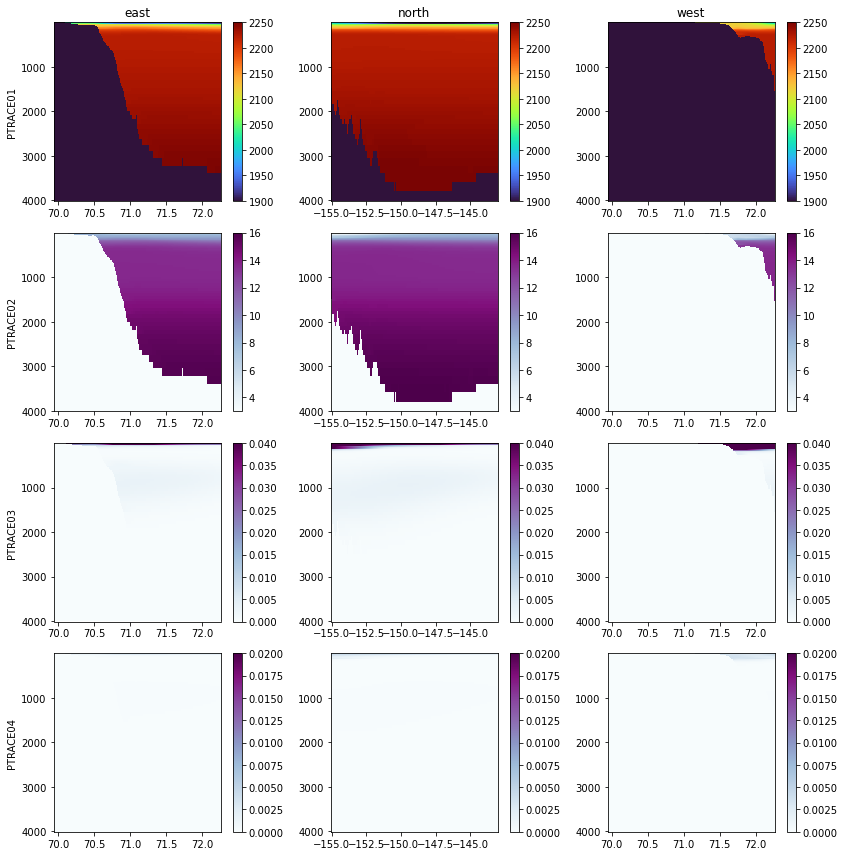

In [31]:
fig = plt.figure(figsize=(12,12))

plot_variable_names = ['PTRACE01','PTRACE02','PTRACE03','PTRACE04']

Z = np.cumsum(delR)
plot_counter = 0
for i in range(len(plot_variable_names)):
    variable_name = plot_variable_names[i]
    
    for boundary in boundary_list:
        
        boundary_grid = np.fromfile(os.path.join(input_dir,'obcs',variable_name+'_'+boundary+'.bin'),'>f4')
    
        if boundary in ['west','east']:
            boundary_grid = boundary_grid.reshape((n_timesteps, np.shape(delR)[0],np.shape(XC)[0]))
            boundary_grid = boundary_grid[0, :, :] # choose just the first timestep for plotting
            if boundary=='west':
                x = YC[:,1]
            if boundary=='east':
                x = YC[:,-1]
        else:
            boundary_grid = boundary_grid.reshape((n_timesteps, np.shape(delR)[0],np.shape(XC)[1]))
            boundary_grid = boundary_grid[0, :, :] # choose just the first timestep for plotting
            if boundary=='north':
                x = XC[-1,:]
            if boundary=='south':
                x = XC[1,:]

        plot_counter += 1
        plt.subplot(len(plot_variable_names),len(boundary_list),plot_counter)
        C = plt.pcolormesh(x, Z, boundary_grid,
                           vmin=meta_dict[variable_name][0],
                           vmax=meta_dict[variable_name][1],
                           cmap=meta_dict[variable_name][2])
        plt.colorbar(C,fraction=0.26)
        plt.gca().invert_yaxis()
    
        if plot_counter%3==1:
            plt.ylabel(variable_name)
        if plot_counter<4:
            plt.title(boundary)

plt.tight_layout()

plt.show()

#### Sea ice

Finally, we'll plot the sea ice boundary conditions:

In [32]:
meta_dict = {'AREA':[0,1],
            'HEFF':[0,1.5],
            'HSNOW':[0, 0.2],
            'UICE':[-0.1, 0.1],
            'VICE':[-0.1, 0.1]}

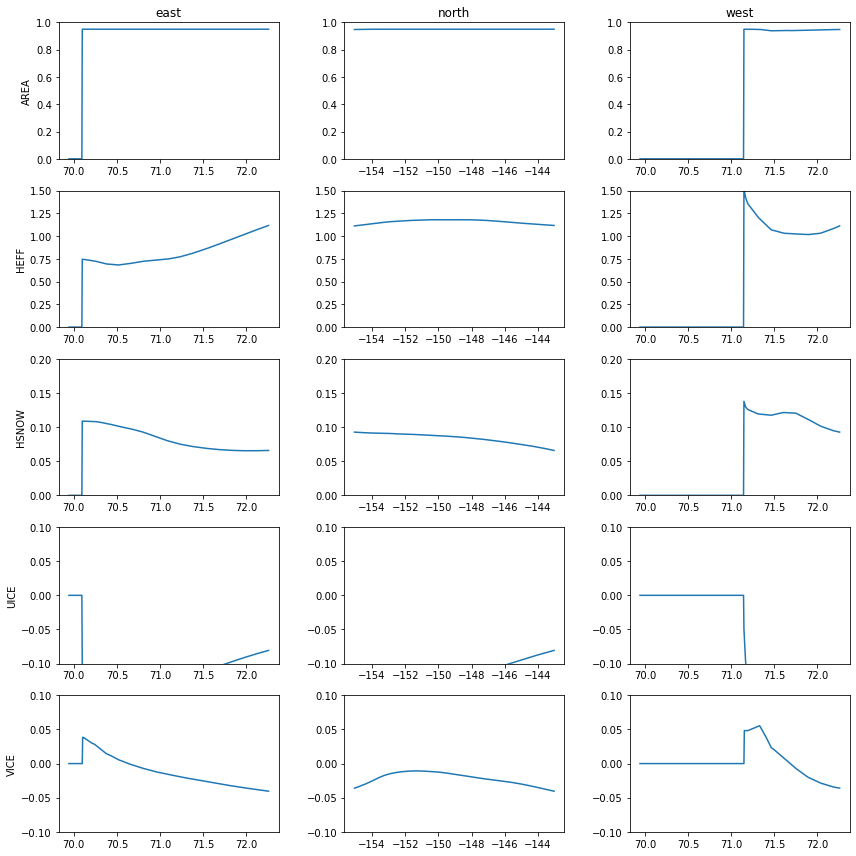

In [33]:
fig = plt.figure(figsize=(12,12))

plot_variable_names = ['AREA','HEFF','HSNOW','UICE','VICE']

Z = np.cumsum(delR)
plot_counter = 0
for i in range(len(plot_variable_names)):
    variable_name = plot_variable_names[i]
    
    for boundary in boundary_list:
        
        boundary_grid = np.fromfile(os.path.join(input_dir,'obcs',
                                                 variable_name+'_'+boundary+'.bin'),'>f4')
    
        if boundary in ['west','east']:
            boundary_grid = boundary_grid.reshape((n_timesteps, np.shape(XC)[0]))
            boundary_grid = boundary_grid[0, :] # choose just the first timestep for plotting
            if boundary=='west':
                x = YC[:,1]
            if boundary=='east':
                x = YC[:,-1]
        else:
            boundary_grid = boundary_grid.reshape((n_timesteps, np.shape(XC)[1]))
            boundary_grid = boundary_grid[0, :] # choose just the first timestep for plotting
            if boundary=='north':
                x = XC[-1,:]
            if boundary=='south':
                x = XC[1,:]

        plot_counter += 1
        plt.subplot(len(plot_variable_names),len(boundary_list),plot_counter)
        plt.plot(x, boundary_grid)
        plt.ylim(meta_dict[variable_name][0],meta_dict[variable_name][1])
    
        if plot_counter%3==1:
            plt.ylabel(variable_name)
        if plot_counter<4:
            plt.title(boundary)

plt.tight_layout()

plt.show()